# Laboratorium 3 — prognozowanie szeregów czasowych

Model GRU, baseline’y oraz wpływ długości okna.

## 1. Dane i przygotowanie zbiorów

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Urządzenie:', DEVICE)


def generuj_sprzedaz(n=1000):
    t = np.arange(n)
    trend = 0.02 * t
    tygodniowa = 8 * np.sin(2 * np.pi * t / 7)
    roczna = 15 * np.sin(2 * np.pi * t / 365)
    szum = np.random.randn(n) * 3
    return (100 + trend + tygodniowa + roczna + szum).astype(np.float32)


seria = generuj_sprzedaz(1000)
n = len(seria)
i_tr = int(0.7 * n)
i_va = int(0.85 * n)
mu, sd = seria[:i_tr].mean(), seria[:i_tr].std()
s = (seria - mu) / sd
OKNO = 28
H = 14


def zrob_okna(s, okno, i_lo, i_hi):
    X, Y = [], []
    for i in range(max(okno, i_lo), i_hi):
        X.append(s[i-okno:i])
        Y.append(s[i])
    return np.array(X, np.float32)[..., None], np.array(Y, np.float32)[:, None]


def przygotuj_okna(okno):
    Xtr, Ytr = zrob_okna(s, okno, okno, i_tr)
    Xva, Yva = zrob_okna(s, okno, i_tr, i_va)
    Xte, Yte = zrob_okna(s, okno, i_va, n)
    to_t = lambda a: torch.tensor(a).to(DEVICE)
    return list(map(to_t, [Xtr, Ytr, Xva, Yva, Xte, Yte]))


dane = przygotuj_okna(OKNO)
print('Podział:', i_tr, i_va, n)
print('Kształty:', dane[0].shape, dane[2].shape, dane[4].shape)

Urządzenie: cpu
Podział: 700 850 1000
Kształty: torch.Size([672, 28, 1]) torch.Size([150, 28, 1]) torch.Size([150, 28, 1])


## 2. Model bazowy i krzywe uczenia

Najlepsza epoka: 37; strata walidacyjna: 0.0822


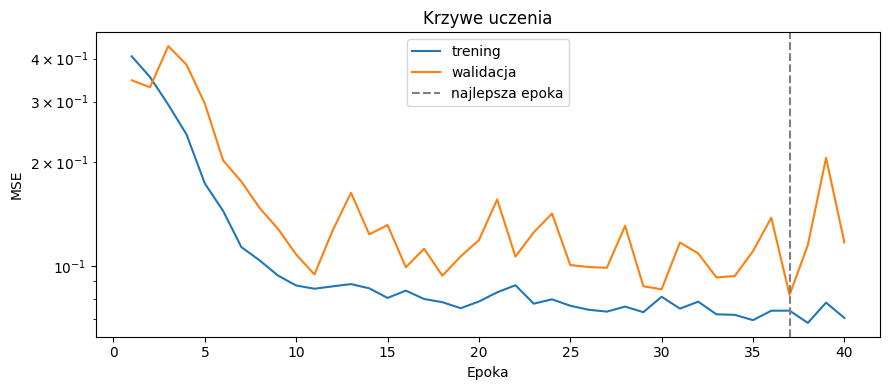

In [ ]:
class ModelGRU(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.rnn = nn.GRU(1, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])


def trenuj(model, Xtr, Ytr, Xva, Yva, epoki=40, lr=1e-2, batch=64):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    L = nn.MSELoss()
    best = float('inf')
    best_state = None
    najlepsza_epoka = 0
    hist_tr, hist_va = [], []

    for ep in range(epoki):
        model.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), batch):
            idx = perm[i:i+batch]
            opt.zero_grad()
            L(model(Xtr[idx]), Ytr[idx]).backward()
            opt.step()

        model.eval()
        with torch.no_grad():
            t = L(model(Xtr), Ytr).item()
            v = L(model(Xva), Yva).item()
        hist_tr.append(t)
        hist_va.append(v)
        if v < best:
            best = v
            najlepsza_epoka = ep + 1
            best_state = {k: val.clone() for k, val in model.state_dict().items()}

    model.load_state_dict(best_state)
    return model, hist_tr, hist_va, najlepsza_epoka


model, hist_tr, hist_va, najlepsza_epoka = trenuj(ModelGRU(32), *dane[:4])
print(f'Najlepsza epoka: {najlepsza_epoka}; strata walidacyjna: {min(hist_va):.4f}')

plt.figure(figsize=(9, 4))
plt.plot(range(1, 41), hist_tr, label='trening')
plt.plot(range(1, 41), hist_va, label='walidacja')
plt.axvline(najlepsza_epoka, color='gray', linestyle='--', label='najlepsza epoka')
plt.xlabel('Epoka')
plt.ylabel('MSE')
plt.yscale('log')
plt.title('Krzywe uczenia')
plt.legend()
plt.tight_layout()
plt.show()

## 3. Porównanie prognozy jednokrokowej

In [ ]:
def mae(a, b):
    return float(np.mean(np.abs(a - b)))


def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))


def prognoza_jednokrokowa(model, Xte):
    model.eval()
    with torch.no_grad():
        pred = model(Xte).cpu().numpy().ravel()
    return pred * sd + mu


Xte, Yte = dane[4], dane[5]
true_raw = Yte.cpu().numpy().ravel() * sd + mu
tgt = np.arange(i_va, n)
wyniki_1 = {
    'GRU': prognoza_jednokrokowa(model, Xte),
    'sezonowy': seria[tgt - 7],
    'naiwny': seria[tgt - 1],
}

print(f'{"Metoda":12s} {"MAE":>8s} {"RMSE":>8s}')
for nazwa, pred in wyniki_1.items():
    print(f'{nazwa:12s} {mae(true_raw, pred):8.2f} {rmse(true_raw, pred):8.2f}')

Metoda            MAE     RMSE
GRU              2.91     3.54
sezonowy         3.21     4.07
naiwny           5.44     6.51


## 4. Prognoza wielokrokowa na teście

Liczba startów: 10; horyzont: 14 dni
Metoda          MAE 1   RMSE 1   MAE 14  RMSE 14
GRU              2.91     3.54     3.88     4.75
sezonowy         3.21     4.07     3.52     4.42
naiwny           5.44     6.51    10.09    11.85


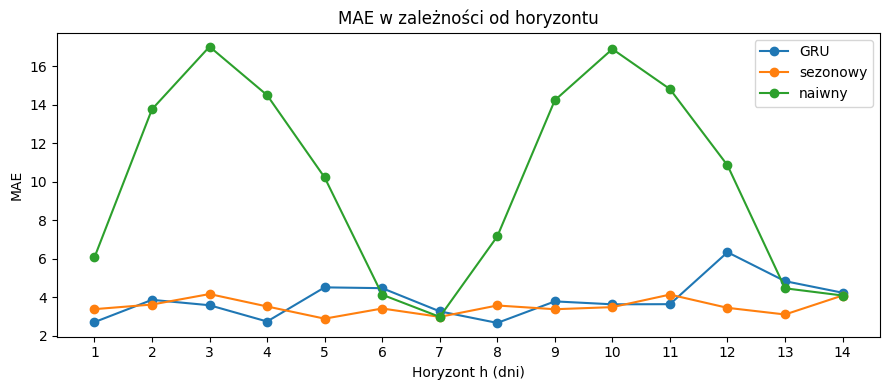

In [ ]:
def rollout(model, t0, okno):
    wartosci = s[t0-okno:t0].tolist()
    preds = []
    model.eval()
    for _ in range(H):
        dane_x = np.array(wartosci[-okno:], np.float32).reshape(1, okno, 1)
        x = torch.tensor(dane_x).to(DEVICE)
        with torch.no_grad():
            nx = model(x).item()
        preds.append(nx)
        wartosci.append(nx)
    return np.array(preds) * sd + mu


def ocena_wielokrokowa(model, okno):
    prawda, gru, sezonowy, naiwny = [], [], [], []
    for t0 in range(i_va, n - H + 1, H):
        prawda.append(seria[t0:t0+H])
        gru.append(rollout(model, t0, okno))
        sezonowy.append([seria[t0 - 7 + h % 7] for h in range(H)])
        naiwny.append([seria[t0 - 1]] * H)
    return np.array(prawda), {
        'GRU': np.array(gru),
        'sezonowy': np.array(sezonowy),
        'naiwny': np.array(naiwny),
    }


prawda_14, wyniki_14 = ocena_wielokrokowa(model, OKNO)
print(f'Liczba startów: {len(prawda_14)}; horyzont: {H} dni')
print(f'{"Metoda":12s} {"MAE 1":>8s} {"RMSE 1":>8s} {"MAE 14":>8s} {"RMSE 14":>8s}')
for nazwa in wyniki_1:
    p1, p14 = wyniki_1[nazwa], wyniki_14[nazwa]
    print(f'{nazwa:12s} {mae(true_raw, p1):8.2f} {rmse(true_raw, p1):8.2f} '
          f'{mae(prawda_14, p14):8.2f} {rmse(prawda_14, p14):8.2f}')

plt.figure(figsize=(9, 4))
for nazwa, p14 in wyniki_14.items():
    mae_h = np.mean(np.abs(prawda_14 - p14), axis=0)
    plt.plot(range(1, H + 1), mae_h, marker='o', label=nazwa)
plt.xticks(range(1, H + 1))
plt.xlabel('Horyzont h (dni)')
plt.ylabel('MAE')
plt.title('MAE w zależności od horyzontu')
plt.legend()
plt.tight_layout()
plt.show()

## 5. Wpływ długości okna (ziarna 0 i 1)

In [ ]:
eksperymenty = []
for okno_test in [3, 7, 28]:
    Xtr, Ytr, Xva, Yva, Xte, Yte = przygotuj_okna(okno_test)
    true = Yte.cpu().numpy().ravel() * sd + mu
    for ziarno in [0, 1]:
        torch.manual_seed(ziarno)
        m, _, hist_v, ep = trenuj(ModelGRU(32), Xtr, Ytr, Xva, Yva)
        p1 = prognoza_jednokrokowa(m, Xte)
        prawda, p14 = ocena_wielokrokowa(m, okno_test)
        eksperymenty.append((okno_test, ziarno, min(hist_v),
                             mae(true, p1), mae(prawda, p14['GRU'])))

print(f'{"Okno":>4s} {"Ziarno":>6s} {"MSE wal.":>10s} {"MAE 1":>8s} {"MAE 14":>8s}')
for okno_test, ziarno, wal, m1, m14 in eksperymenty:
    print(f'{okno_test:4d} {ziarno:6d} {wal:10.4f} {m1:8.2f} {m14:8.2f}')

srednia_wal = {
    okno_test: float(np.mean([r[2] for r in eksperymenty if r[0] == okno_test]))
    for okno_test in [3, 7, 28]
}
najlepsze_okno = min(srednia_wal, key=srednia_wal.get)
print('Średnie straty walidacyjne:',
      {k: round(v, 4) for k, v in srednia_wal.items()})
print('Najlepsze okno według walidacji:', najlepsze_okno)

Okno Ziarno   MSE wal.    MAE 1   MAE 14
   3      0     0.2567     5.00     7.18
   3      1     0.2486     5.04     7.41
   7      0     0.0855     2.90     4.21
   7      1     0.0896     2.88     3.89
  28      0     0.0822     2.91     3.88
  28      1     0.0850     3.01     4.29
Średnie straty walidacyjne: {3: 0.2527, 7: 0.0876, 28: 0.0836}
Najlepsze okno według walidacji: 28
